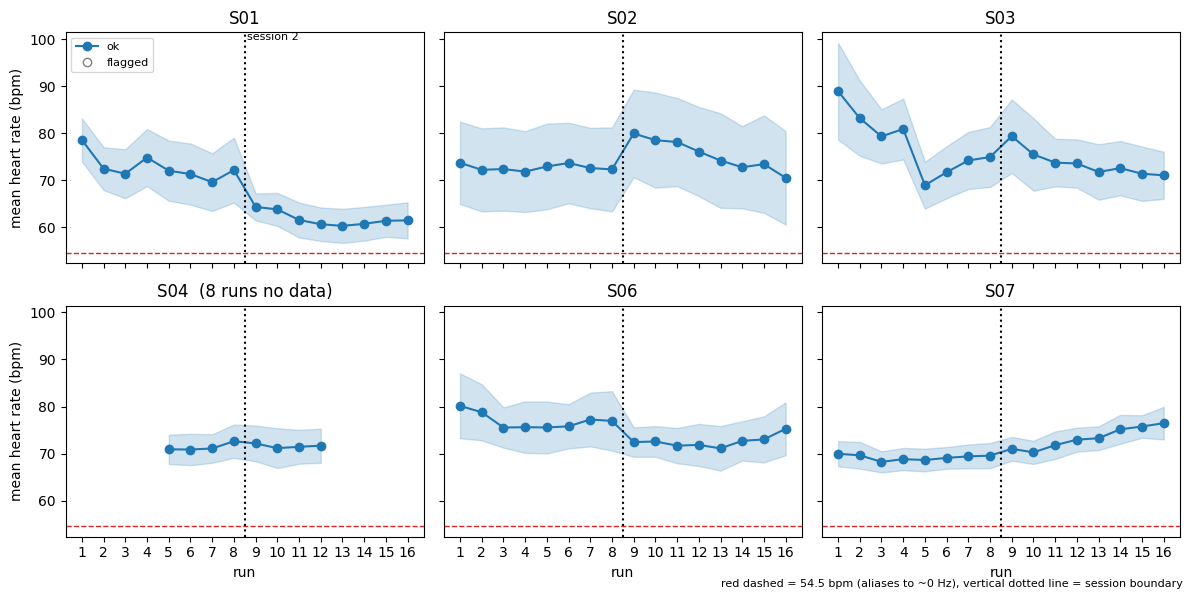

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]    

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, s in zip(axes, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    # line through good runs only; flagged or missing runs leave a gap
    ax.plot(x.run, x.hr_mean.where(good), '-o', color='C0', label='ok')
    ax.fill_between(x.run, (x.hr_mean - x.hr_sd).where(good),
                    (x.hr_mean + x.hr_sd).where(good), color='C0', alpha=0.2)

    # flagged runs (data present but failed QC) as open grey markers
    flagged = ~good & x.hr_mean.notna()
    ax.plot(x.run[flagged], x.hr_mean[flagged], 'o', mfc='none', color='0.5', label='flagged')

    # heart rate whose aliased frequency is ~0 Hz with TR = 1.1 s
    ax.axhline(60 / 1.1, color='C3', ls='--', lw=1)
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2

    n_missing = x.hr_mean.isna().sum()
    ax.set_title(f'{s}' + (f'  ({n_missing} runs no data)' if n_missing else ''))
    ax.set_xticks(range(1, 17))

for ax in axes[n:]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes[::ncol]:
    ax.set_ylabel('mean heart rate (bpm)')

axes[0].legend(fontsize=8, loc='upper left')
fig.text(0.99, 0.01, 'red dashed = 54.5 bpm (aliases to ~0 Hz), vertical dotted line = session boundary', va='bottom',
         ha='right', fontsize=8)

axes[0].text(8.6, axes[0].get_ylim()[1], 'session 2', va='top', fontsize=8)

plt.tight_layout()
plt.show()

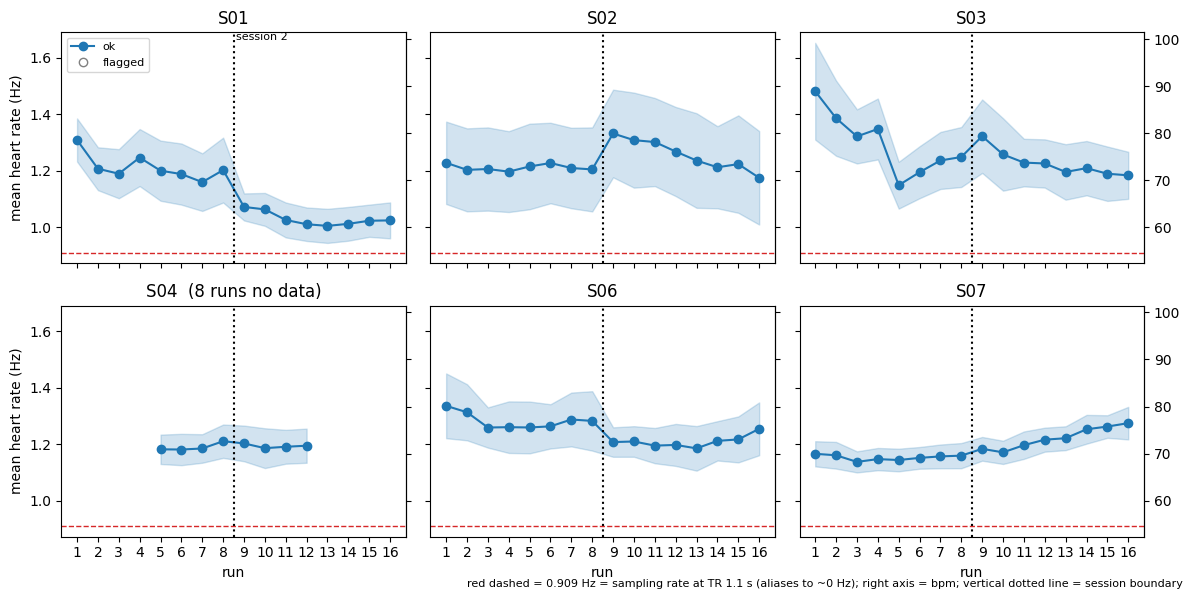

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TR = 1.1
fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]
T['hr_hz'] = T.hr_mean / 60          # mean heart rate in Hz
T['hr_sd_hz'] = T.hr_sd / 60         # its spread within the run, in Hz

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, s in zip(axes, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    # line through good runs only; flagged or missing runs leave a gap
    ax.plot(x.run, x.hr_hz.where(good), '-o', color='C0', label='ok')
    ax.fill_between(x.run, (x.hr_hz - x.hr_sd_hz).where(good),
                    (x.hr_hz + x.hr_sd_hz).where(good), color='C0', alpha=0.2)

    # flagged runs (data present but failed QC) as open grey markers
    flagged = ~good & x.hr_hz.notna()
    ax.plot(x.run[flagged], x.hr_hz[flagged], 'o', mfc='none', color='0.5', label='flagged')

    # heart rate whose aliased frequency is ~0 Hz: the sampling rate 1/TR
    ax.axhline(1 / TR, color='C3', ls='--', lw=1)
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2

    # bpm on the right-hand axis, for reference
    sec = ax.secondary_yaxis('right', functions=(lambda hz: hz * 60, lambda bpm: bpm / 60))
    if ax not in axes[ncol - 1::ncol] and ax is not axes[n - 1]:
        sec.set_yticklabels([])

    n_missing = x.hr_hz.isna().sum()
    ax.set_title(f'{s}' + (f'  ({n_missing} runs no data)' if n_missing else ''))
    ax.set_xticks(range(1, 17))

for ax in axes[n:]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes[::ncol]:
    ax.set_ylabel('mean heart rate (Hz)')

axes[0].legend(fontsize=8, loc='upper left')
fig.text(0.99, 0.01, f'red dashed = {1/TR:.3f} Hz = sampling rate at TR {TR} s (aliases to ~0 Hz); '
         'right axis = bpm; vertical dotted line = session boundary',
         va='bottom', ha='right', fontsize=8)

axes[0].text(8.6, axes[0].get_ylim()[1], 'session 2', va='top', fontsize=8)

plt.tight_layout()
plt.show()

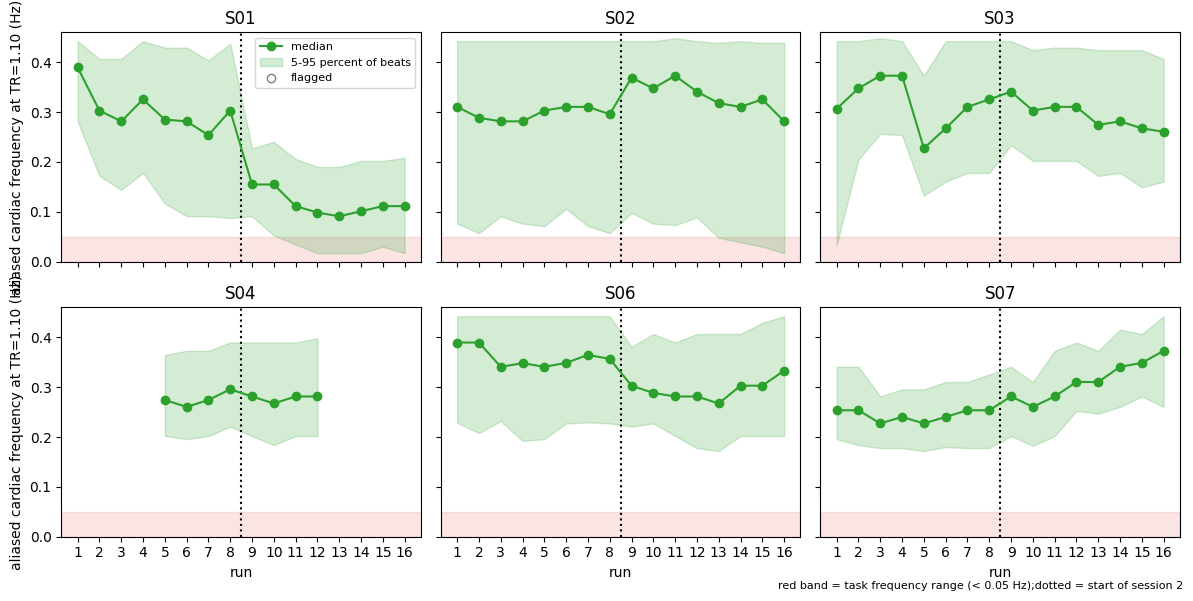

In [18]:

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]    

fig2, axes2 = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes2 = np.atleast_1d(axes2).ravel()

for ax, s in zip(axes2, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    ax.axvline(8.5, color='k', ls=':', lw=1.5)                 # start of session 2
    ax.axhspan(0, 0.05, color='C3', alpha=0.12, zorder=0)      # task frequency range

    ax.plot(x.run, x.alias_med.where(good), '-o', color='C2', label='median')
    ax.fill_between(x.run, x.alias_p05.where(good), x.alias_p95.where(good),
                    color='C2', alpha=0.2, label='5-95 percent of beats')

    flagged = ~good & x.alias_med.notna()
    ax.plot(x.run[flagged], x.alias_med[flagged], 'o', mfc='none', color='0.5', label='flagged')

    ax.set_title(s)
    ax.set_xticks(range(1, 17))
    ax.set_ylim(0, 0.46)

for ax in axes2[n:]:
    ax.set_visible(False)
for ax in axes2[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes2[::ncol]:
    ax.set_ylabel('aliased cardiac frequency at TR=1.10 (Hz)')

axes2[0].legend(fontsize=8, loc='upper right')
fig2.text(0.99, 0.01, 'red band = task frequency range (< 0.05 Hz);'
          'dotted = start of session 2', ha='right', fontsize=8)
plt.tight_layout()
plt.show()

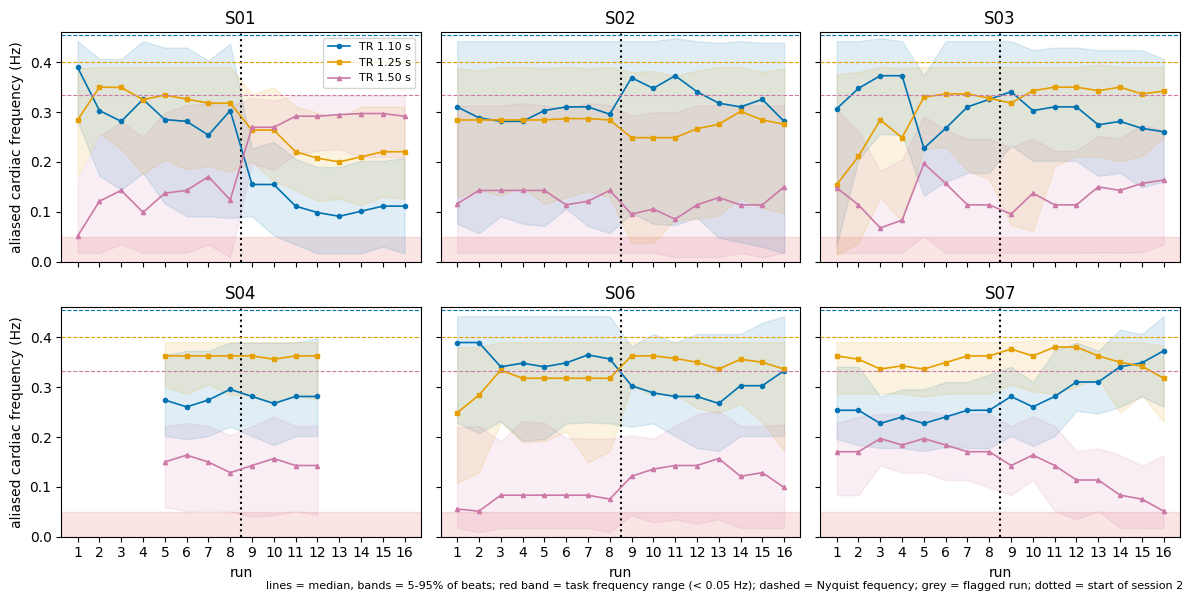

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_{}.tsv'
trs = {'1_10': (1.10, '#0072B2', 'o'),          # file tag: (TR in s, colour)
       '1_25': (1.25, '#E69F00', 's'),
       '1_50': (1.50, '#CC79A7', '^')}

# ---- load all three tables ----
tabs = {}
for tag, (tr, col, mk) in trs.items():
    T = pd.read_csv(base.format(tag), sep='\t')
    tabs[tag] = T[~T.subj.isin(['S05', 'S09'])]

subjects = tabs['1_10'].subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig2, axes2 = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes2 = np.atleast_1d(axes2).ravel()

for ax, s in zip(axes2, subjects):
    ax.axvline(8.5, color='k', ls=':', lw=1.5)                 # start of session 2
    ax.axhspan(0, 0.05, color='C3', alpha=0.12, zorder=0)      # task frequency range

    # flagged runs (same for every TR): grey background
    x0 = tabs['1_10'][tabs['1_10'].subj == s]
    for r in x0.run[(x0.status != 'ok') & x0.alias_med.notna()]:
        ax.axvspan(r - 0.5, r + 0.5, color='0.85', zorder=0)

    for tag, (tr, col, mk) in trs.items():
        x = tabs[tag][tabs[tag].subj == s].sort_values('run')
        good = x.status == 'ok'
        ax.plot(x.run, x.alias_med.where(good), marker=mk, color=col, ms=3, lw=1.2,
                label=f'TR {tr:.2f} s')
        ax.fill_between(x.run, x.alias_p05.where(good), x.alias_p95.where(good),
                        color=col, alpha=0.12)
        ax.axhline(1 / (2 * tr), color=col, ls='--', lw=0.8)   # Nyquist: highest possible alias

    ax.set_title(s)
    ax.set_xticks(range(1, 17))
    ax.set_ylim(0, 0.46)

for ax in axes2[n:]:
    ax.set_visible(False)
for ax in axes2[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes2[::ncol]:
    ax.set_ylabel('aliased cardiac frequency (Hz)')

axes2[0].legend(fontsize=8, loc='upper right')
fig2.text(0.99, 0.01, 'lines = median, bands = 5-95% of beats; red band = task frequency range (< 0.05 Hz); '
          'dashed = Nyquist fequency; grey = flagged run; dotted = start of session 2',
          ha='right', fontsize=8)
plt.tight_layout()
plt.show()